# 02. Качество: где возникает брак и почему

**Вопрос бизнеса.** ОТК фиксирует рост доработок в ЦЛА с конца 2025 года. Нужно найти, *где* именно возникают дефекты (участок, смена, бригада), *почему* - и оценить, сколько это стоит.

**Метрика.** Дефектность операции - доля операций, которые прослежены как источник дефекта (найденного на линии ОТК или позже на испытаниях). Прослеживание идёт по `origin_operation_id`: дефект, пойманный на испытаниях, «возвращается» к операции и бригаде, которая его допустила.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.formula.api as smf
from scipy.optimize import curve_fit
from helpers import q, save, pct, label_ends, BLUE, ORANGE, AQUA, GRAY, GRAY_LIGHT, INK_2

## 1. Карта дефектности: участок × смена × квартал

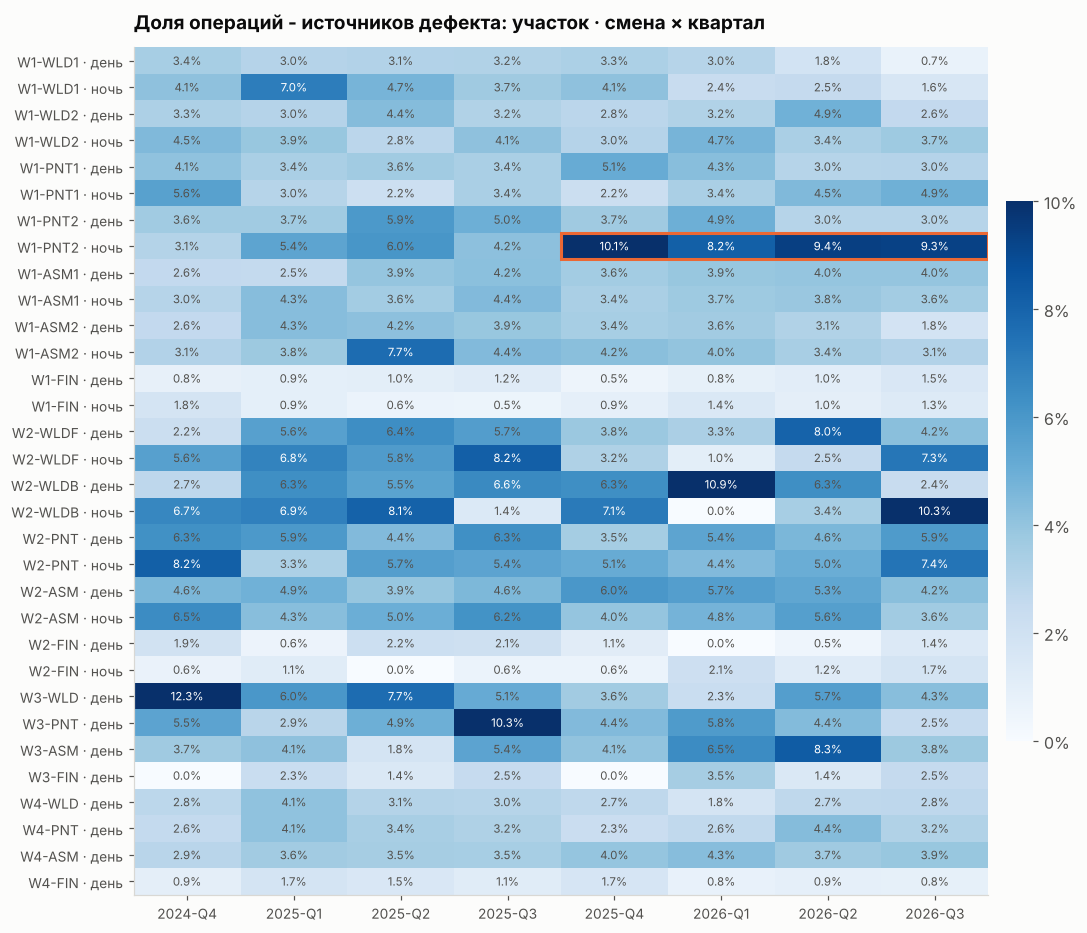

In [2]:
heat = q("""
select s.section_code || ' · ' || case o.shift when 'day' then 'день' else 'ночь' end as line,
       s.section_id,
       to_char(date_trunc('quarter', o.work_date), 'YYYY-"Q"Q') as quarter,
       avg(o.caused_defect::int) as defect_rate, count(*) as ops
from marts.fct_operations o join marts.dim_section s using (section_id)
where not o.is_rework and o.work_date < '2026-10-01'
group by 1, 2, 3
""")
hp = heat.pivot(index=["section_id", "line"], columns="quarter", values="defect_rate").sort_index()
hp.index = hp.index.get_level_values(1)

fig, ax = plt.subplots(figsize=(10, 8.6))
im = ax.imshow(hp.values, cmap="Blues", aspect="auto", vmin=0, vmax=0.10)
ax.set_xticks(range(hp.shape[1]), hp.columns, rotation=0, fontsize=9)
ax.set_yticks(range(hp.shape[0]), hp.index, fontsize=9)
ax.grid(False)
for i in range(hp.shape[0]):
    for j in range(hp.shape[1]):
        v = hp.values[i, j]
        if np.isfinite(v):
            ax.text(j, i, f"{v:.1%}", ha="center", va="center", fontsize=7.5,
                    color="white" if v > 0.065 else INK_2)
row = list(hp.index).index("W1-PNT2 · ночь")
ax.add_patch(plt.Rectangle((hp.columns.get_loc("2025-Q4") - 0.5, row - 0.5), 4, 1, fill=False, ec=ORANGE, lw=2))
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, format=lambda x, _: f"{x:.0%}")
cb.outline.set_visible(False)
ax.set_title("Доля операций - источников дефекта: участок · смена × квартал")
save(fig, "02_defect_heatmap")

На фоне стабильных 2-5% выделяется одна клетка-полоса: **окрасочный участок №2 ЦЛА, ночная смена, начиная с IV квартала 2025** - дефектность выросла примерно вдвое и не вернулась. Дневная смена того же участка (то же оборудование, те же модели и материалы) осталась на прежнем уровне - значит, дело не в оборудовании и не в изделии, а в людях или организации смены.

Заметны и «тёплые» полосы на сварке ЦСТ и ЦГА (там исходно выше дефектность - крупногабаритная сварка) - к ним вернёмся в ноутбуке 03.

## 2. Ночная бригада окраски №2: что изменилось

In [3]:
br = q("""
select month_start, brigade_name, shift, operations, defect_operations, defect_rate,
       avg_tenure_days, avg_newcomer_share, avg_members
from marts.mart_quality_brigade_month
where section_id = 4 order by month_start, shift
""")
br.pivot(index="month_start", columns="shift", values=["defect_rate", "avg_newcomer_share"]).loc["2025-06-01":].round(3)

defect_rate        avg_newcomer_share       
shift               day  night                day  night
month_start                                             
2025-06-01        0.070  0.022              0.167  0.000
2025-07-01        0.068  0.035              0.148  0.000
2025-08-01        0.028  0.047              0.167  0.000
2025-09-01        0.049  0.043              0.167  0.000
2025-10-01        0.039  0.108              0.073  0.608
2025-11-01        0.042  0.072              0.000  1.000
2025-12-01        0.029  0.116              0.000  1.000
2026-01-01        0.067  0.059              0.000  0.729
2026-02-01        0.043  0.112              0.000  0.498
2026-03-01        0.045  0.072              0.000  0.576
2026-04-01        0.021  0.107              0.000  0.478
2026-05-01        0.040  0.086              0.000  0.432
2026-06-01        0.028  0.087              0.000  0.396
2026-07-01        0.060  0.093              0.000  0.553
2026-08-01        0.008  0.091              0.000  0.546
2026-09-01        0.014  0.095              0.000  0.475

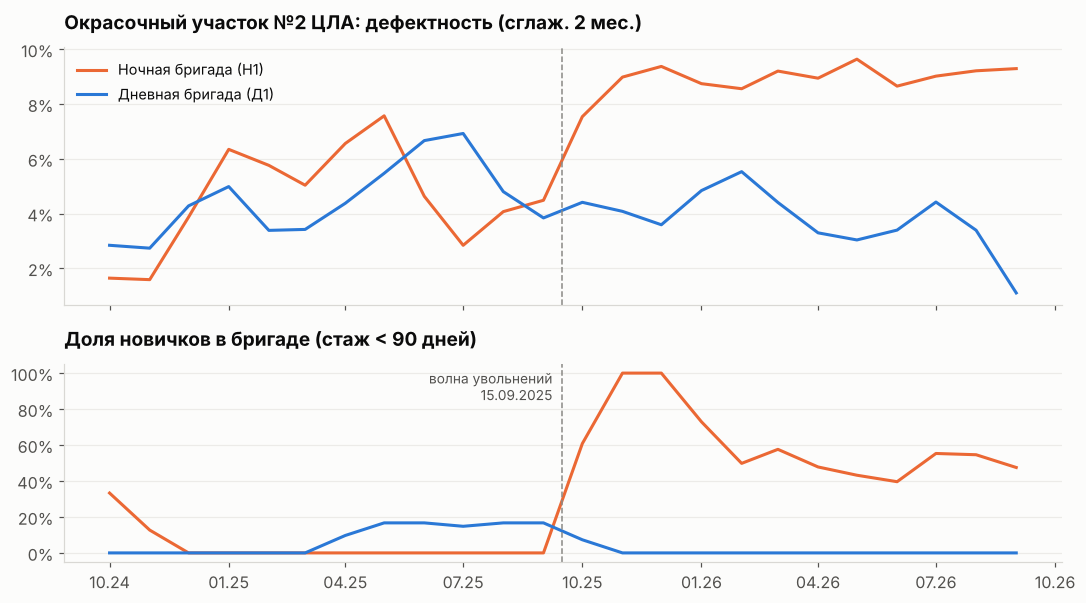

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
for shift, color, name in [("night", ORANGE, "Ночная бригада (Н1)"), ("day", BLUE, "Дневная бригада (Д1)")]:
    d = br[br["shift"] == shift].set_index("month_start")
    axes[0].plot(d.index, d["defect_rate"].rolling(2, min_periods=1).mean(), color=color, label=name)
    axes[1].plot(d.index, d["avg_newcomer_share"], color=color, label=name)
pct(axes[0], 0)
pct(axes[1], 0)
axes[0].set_title("Окрасочный участок №2 ЦЛА: дефектность (сглаж. 2 мес.)")
axes[1].set_title("Доля новичков в бригаде (стаж < 90 дней)")
axes[0].legend(loc="upper left")
for ax in axes:
    ax.axvline(pd.Timestamp("2025-09-15"), color=GRAY, lw=1, ls="--")
axes[1].annotate("волна увольнений\n15.09.2025", (pd.Timestamp("2025-09-15"), 0.85), xytext=(-6, 0),
                 textcoords="offset points", fontsize=9, color=INK_2, ha="right")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m.%y"))
save(fig, "02_problem_brigade")

In [5]:
mem = q("""
select b.brigade_name, e.full_name, m.valid_from, m.valid_to, e.hire_date
from staging.stg_plant__brigade_memberships m
join marts.dim_brigade b using (brigade_id)
join staging.stg_plant__employees e using (employee_id)
where b.section_id = 4 and b.shift = 'night' and (m.valid_to is null or m.valid_to >= '2025-06-01')
order by m.valid_from
""")
mem["days_in_brigade"] = (mem["valid_to"].fillna(pd.Timestamp("2026-09-30")) - mem["valid_from"]).dt.days
print(f"Ночная бригада Н1: с июня 2025 через неё прошло {len(mem)} человек при штате 5-6.")
print("Медиана срока работы пришедших после 15.09.2025:",
      int(mem.loc[mem['valid_from'] >= '2025-09-15', 'days_in_brigade'].median()), "дн.")
mem.tail(10)

Ночная бригада Н1: с июня 2025 через неё прошло 26 человек при штате 5-6.
Медиана срока работы пришедших после 15.09.2025: 59 дн.


,brigade_name,full_name,valid_from,valid_to,hire_date,days_in_brigade
16,Бригада W1-PNT2-Н1,Захарова Татьяна Леонидовна,2026-02-22,2026-03-20,2026-02-22,26
17,Бригада W1-PNT2-Н1,Гаврилов Андрей Николаевич,2026-03-01,2026-06-16,2026-03-01,107
18,Бригада W1-PNT2-Н1,Казаков Александр Михайлович,2026-03-25,2026-04-26,2026-03-25,32
19,Бригада W1-PNT2-Н1,Ильин Пётр Романович,2026-05-02,2026-07-15,2026-05-02,74
20,Бригада W1-PNT2-Н1,Николаев Алексей Леонидович,2026-05-22,NaT,2026-05-22,131
21,Бригада W1-PNT2-Н1,Быкова Алина Ивановна,2026-06-25,2026-08-27,2026-06-25,63
22,Бригада W1-PNT2-Н1,Воробьёв Евгений Михайлович,2026-07-24,2026-08-04,2026-07-24,11
23,Бригада W1-PNT2-Н1,Воронина Дарья Вячеславовна,2026-08-05,NaT,2026-08-05,56
24,Бригада W1-PNT2-Н1,Герасимов Максим Павлович,2026-08-16,NaT,2026-08-16,45
25,Бригада W1-PNT2-Н1,Ковалёв Кирилл Григорьевич,2026-09-13,NaT,2026-09-13,17


Механизм виден напрямую: в сентябре-октябре 2025 из ночной бригады ушли почти все опытные маляры, а пришедшие новички сами уходят через 2-3 месяца - доля новичков держится на уровне 60-100%, и дефектность следует за ней. Дневная бригада стабильна по составу и по качеству.

## 3. Проверка гипотезы на всём заводе: модель дефекта операции
Одна бригада - это «кейс». Чтобы утверждать, что стаж - фактор, а не совпадение, оценим логистическую регрессию на всех 110 тыс. операциях и **отделим** эффект доли новичков от смены, «штурмовщины», возраста бригады, типа участка и категории изделия.

In [6]:
ops = q("""
select o.caused_defect::int as defect, o.brigade_newcomer_share as newcomers, (o.shift = 'night')::int as night,
       o.is_month_end_rush::int as rush, ln(1 + o.brigade_age_days) as log_brigade_age, o.section_type,
       dm.category_code as category, (o.ws2_group = 'pilot' and o.is_ws2_post_period)::int as ws2,
       extract(epoch from (o.work_date - date '2024-10-01') * interval '1 day') / 86400 / 365.25 as years
from marts.fct_operations o join marts.dim_model dm using (model_id)
where not o.is_rework
""")
ops["newcomers_10pp"] = ops["newcomers"] * 10
model = smf.logit("defect ~ newcomers_10pp + night + rush + log_brigade_age + ws2 + years"
                  " + C(section_type) + C(category)", data=ops).fit(disp=False)
ci = np.exp(model.conf_int())
odds = pd.DataFrame({"Отношение шансов": np.exp(model.params), "95% ДИ низ": ci[0], "95% ДИ верх": ci[1],
                     "p-value": model.pvalues}).loc[["newcomers_10pp", "night", "rush", "log_brigade_age", "ws2"]]
odds.index = ["+10 п.п. новичков в бригаде", "Ночная смена", "Последние 3 раб. дня месяца",
              "Возраст бригады (log дней)", "Сварка по стандарту WS-2"]
odds.round(3)

,Отношение шансов,95% ДИ низ,95% ДИ верх,p-value
+10 п.п. новичков в бригаде,1.111,1.090,1.133,0.000
Ночная смена,1.100,1.017,1.191,0.018
Последние 3 раб. дня месяца,1.433,1.328,1.545,0.000
Возраст бригады (log дней),0.972,0.927,1.020,0.248
Сварка по стандарту WS-2,0.686,0.569,0.828,0.000


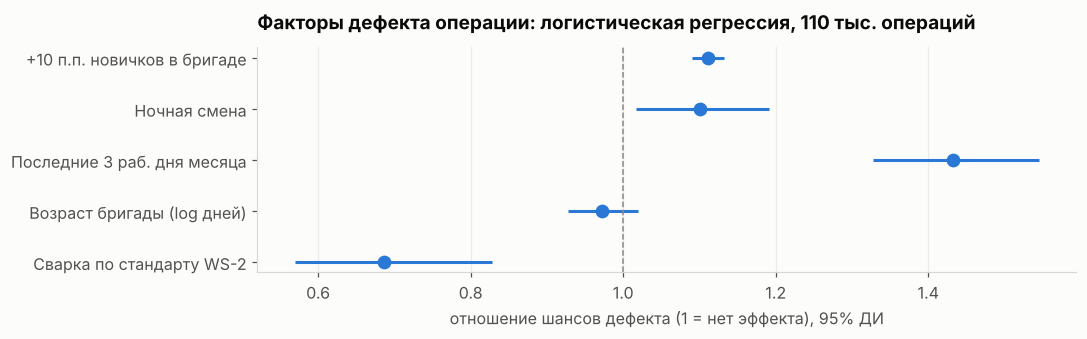

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.2))
y = np.arange(len(odds))[::-1]
ax.hlines(y, odds["95% ДИ низ"], odds["95% ДИ верх"], color=BLUE, lw=2)
ax.plot(odds["Отношение шансов"], y, "o", color=BLUE, ms=8)
ax.axvline(1, color=GRAY, lw=1, ls="--")
ax.set_yticks(y, odds.index)
ax.grid(axis="x", color="#ecebe8")
ax.grid(axis="y", visible=False)
ax.set_xlabel("отношение шансов дефекта (1 = нет эффекта), 95% ДИ")
ax.set_title("Факторы дефекта операции: логистическая регрессия, 110 тыс. операций")
save(fig, "02_logit_odds")

**Что говорит модель** (при прочих равных):
* каждые +10 п.п. новичков в бригаде повышают шансы дефекта на ~11%: у бригады из одних новичков шансы дефекта почти втрое выше, чем у опытной; эффект общий для завода, а не только для окраски №2;
* конец месяца (+~40%) и ночная смена (+~10%) - самостоятельные факторы;
* «молодость» бригады отдельно почти не значима, если учтён стаж людей: молодая бригада плоха потому, что в ней новички;
* стандарт сварки WS-2 снижает шансы дефекта - его отдельно и корректно оценим в ноутбуке 03.

Ограничение: это наблюдательные данные, модель показывает связь при контроле перечисленных факторов. Причинность здесь подкрепляется механизмом (волна увольнений по времени предшествует росту брака, дневная смена - естественный контроль).

## 4. Кривая обучения новой бригады
В апреле 2025 на сборке №2 ЦЛА создана третья ночная бригада (рост выпуска «Вектора»). Сколько времени ей понадобилось, чтобы выйти на норматив?

Кривая обучения: старт 75% от уровня зрелой бригады, 95% достигается через 11.0 нед. (~77 дн.); зрелый уровень 0.97 vs остальные бригады 1.00
Дефектность по 2-месячным периодам: {0: 4.2, 1: 3.0, 2: 1.6, 3: 2.3, 4: 0.8, 5: 0.9, 6: 1.2} (кратно среднему по участку)


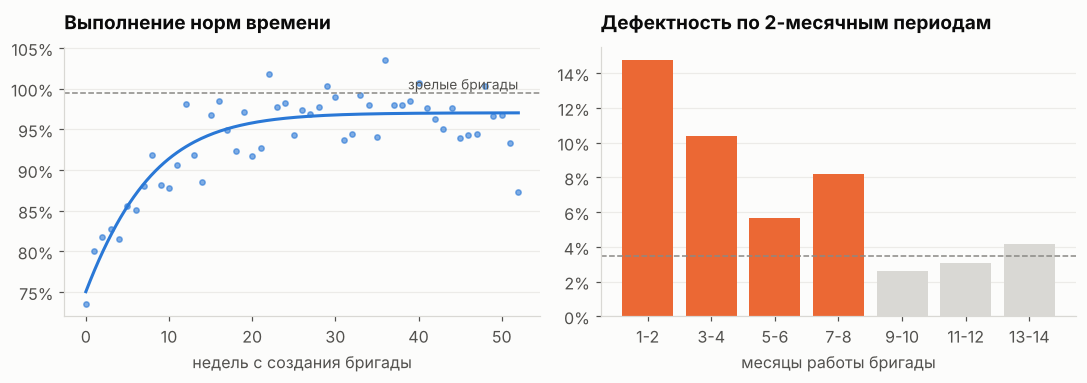

In [8]:
lc = q("""
select (o.brigade_age_days / 7)::int as week, avg(o.std_to_actual_ratio) as efficiency,
       avg(o.caused_defect::int) as defect_rate, count(*) as ops
from marts.fct_operations o join marts.dim_brigade b using (brigade_id)
where b.brigade_name = 'Бригада W1-ASM2-Н3' and not o.is_rework and o.brigade_age_days < 365
group by 1 order by 1
""")
base = q("""
select avg(std_to_actual_ratio) as eff, avg(caused_defect::int) as dr from marts.fct_operations o
join marts.dim_brigade b using (brigade_id)
where b.section_id = 6 and b.brigade_name <> 'Бригада W1-ASM2-Н3' and not o.is_rework and o.work_date >= '2025-04-07'
""").iloc[0]

f = lambda t, a, tau, c: c / (1 + a * np.exp(-t / tau))
(a_, tau_, c_), _ = curve_fit(f, lc["week"], lc["efficiency"], p0=(0.3, 6, 1), sigma=1 / np.sqrt(lc["ops"]))
t95 = -tau_ * np.log((1 / 0.95 - 1) / a_)
print(f"Кривая обучения: старт {f(0, a_, tau_, c_):.0%} от уровня зрелой бригады, "
      f"95% достигается через {t95:.1f} нед. (~{t95 * 7:.0f} дн.); зрелый уровень {c_:.2f} vs остальные бригады {base.eff:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].scatter(lc["week"], lc["efficiency"], s=12, color=BLUE, alpha=0.6)
tt = np.linspace(0, lc["week"].max(), 200)
axes[0].plot(tt, f(tt, a_, tau_, c_), color=BLUE)
axes[0].axhline(base.eff, color=GRAY, ls="--", lw=1)
axes[0].text(lc["week"].max(), base.eff, "зрелые бригады", va="bottom", ha="right", fontsize=9, color=INK_2)
pct(axes[0])
axes[0].set_title("Выполнение норм времени")
axes[0].set_xlabel("недель с создания бригады")
grp = lc.assign(m=lc["week"] // 8, d=lc["defect_rate"] * lc["ops"]).groupby("m")[["d", "ops"]].sum()
grp = grp[grp["ops"] >= 120]                    # ~100 операций в месяц: берём 2-месячные периоды, неполный отбрасываем
mon = grp["d"] / grp["ops"]
print("Дефектность по 2-месячным периодам:", (mon / base.dr).round(1).to_dict(), "(кратно среднему по участку)")
axes[1].bar([f"{2 * i + 1}-{2 * i + 2}" for i in mon.index], mon.values, color=[ORANGE if v > base.dr * 1.3 else GRAY_LIGHT for v in mon.values])
axes[1].axhline(base.dr, color=GRAY, ls="--", lw=1)
pct(axes[1], 0)
axes[1].set_title("Дефектность по 2-месячным периодам")
axes[1].set_xlabel("месяцы работы бригады")
save(fig, "02_learning_curve")

Новая бригада стартует с выполнением норм ~75% и выходит на 95% уровня зрелой бригады примерно за 11 недель (~2.5 месяца). С качеством дольше: первые 2 месяца дефектность в ~4 раза выше средней по участку, в 3-4-м месяце - в ~3 раза, и только к 9-му месяцу выходит на уровень участка - бригада целиком из новичков, а стаж людей (см. модель выше) важнее «возраста» бригады. Это «цена входа» в любое расширение смены: её нужно закладывать в план (сниженный такт на период освоения, 1-2 опытных сборщика в состав новой бригады вместо набора целиком с рынка).

## 5. Сколько стоит проблема ночной окраски №2
Сравниваем фактическое число дефектов бригады после 15.09.2025 с ожидаемым при её прежнем уровне дефектности. Стоимость дефекта - фактические доработки + гарантийные выплаты по дефектам ЛКП изделий, окрашенных этой бригадой.

In [9]:
cost = q("""
with b as (
    select o.operation_id, o.unit_id, o.work_date >= '2025-09-15' as post, o.caused_defect
    from marts.fct_operations o join marts.dim_brigade d using (brigade_id)
    where d.brigade_name = 'Бригада W1-PNT2-Н1' and not o.is_rework
),
rates as (
    select post, count(*) as ops, sum(caused_defect::int) as defects from b group by post
),
dcost as (
    select avg(f.rework_cost_rub) as rework_per_defect
    from marts.fct_defects f where f.origin_area = 'PAINT' and f.workshop_id = 1
),
wc as (
    select count(*) filter (where c.status <> 'rejected') as claims, sum(c.approved_amount_rub) as warranty
    from marts.fct_warranty_claims c
    join marts.fct_units u using (unit_id)
    join marts.dim_brigade d on d.brigade_id = u.paint_brigade_id
    where d.brigade_name = 'Бригада W1-PNT2-Н1' and c.origin_area = 'PAINT' and u.start_date >= '2025-09-15'
)
select r1.ops as ops_post, r1.defects as defects_post,
       round(r0.defects::numeric / r0.ops, 4) as rate_pre, round(r1.defects::numeric / r1.ops, 4) as rate_post,
       round(r1.defects - r1.ops * r0.defects::numeric / r0.ops) as excess_defects,
       round(dcost.rework_per_defect) as rework_per_defect_rub,
       wc.claims as paint_claims_post, wc.warranty as paint_warranty_post_rub
from rates r1 join rates r0 on r1.post and not r0.post cross join dcost cross join wc
""")
cost.T

,0
ops_post,2116.0000
defects_post,190.0000
rate_pre,0.0471
rate_post,0.0898
excess_defects,90.0000
rework_per_defect_rub,1651.0000
paint_claims_post,3.0000
paint_warranty_post_rub,157940.0000


In [10]:
c = cost.iloc[0]
excess_share = c.excess_defects / c.defects_post
internal = c.excess_defects * c.rework_per_defect_rub
external = c.paint_warranty_post_rub * excess_share
print(f"Избыточных дефектов: {c.excess_defects:.0f} из {c.defects_post:.0f} за 12.5 мес. (15.09.2025-30.09.2026)")
print(f"Прямые потери: доработки ≈ {internal / 1e3:,.0f} тыс. ₽ + гарантия ≈ {external / 1e3:,.0f} тыс. ₽ "
      f"(гарантийный хвост ещё не проявился полностью - дефекты ЛКП всплывают в среднем через 6-8 мес.)")

Избыточных дефектов: 90 из 190 за 12.5 мес. (15.09.2025-30.09.2026)
Прямые потери: доработки ≈ 149 тыс. ₽ + гарантия ≈ 75 тыс. ₽ (гарантийный хвост ещё не проявился полностью - дефекты ЛКП всплывают в среднем через 6-8 мес.)


**Масштаб в деньгах** относительно невелик (сотни тысяч рублей), но это нижняя граница: не учтены потеря такта на доработках, репутационный ущерб у дилеров и продолжающийся гарантийный хвост по машинам, окрашенным в 2026 году. Главная ценность находки - механизм: **текучесть в одной смене ломает качество быстрее, чем видит ОТК**, а метрика «доля новичков в бригаде» - ранний индикатор, доступный до появления брака.

### Рекомендации
1. **Ночная смена окраски №2:** закрепить 2 опытных маляров из дневной смены как наставников на 3 месяца; до стабилизации - 100% контроль ЛКП после ночной смены.
2. **Удержание:** выяснить у HR причины ухода новичков через 2-3 месяца (условия ночной смены, оплата) - это корень, без него наставничество не поможет.
3. **Правило комплектования:** не более 30% новичков в бригаде на критичных операциях (окраска, сварка); добавить на дашборд мастера индикатор доли новичков.
4. **Новые бригады:** закладывать в план период освоения ~2.5 месяца со сниженным тактом; не комплектовать бригаду целиком из новых сотрудников.
5. **Конец месяца:** выравнивание графика запусков (см. ноутбук 01) - даёт эффект на всех участках сразу.